# Example

Below I am going to walk through my own changes and thought processes. I am writing this before I have tried to create the controller so I guess some things I try will not work and some will work well.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# No need to import anything else from the scaffold, just update it to use mymdoel instead of model.
import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from mymodel import FEATURES, TARGETS, create_model
from safetensors.torch import load_file, save_file
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm # This is just a progress bar for the training loop

In [3]:
landings_path = Path("landings.csv")

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

# I'm not going to set the hyperparameters here because I will tune them for each model.
# learning_rate = 5e-4
# epochs = 60
# batch_size = 256

# I'm adding the device in and using a GPU so I can train faster (hopefully)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
# Load the landings from the path
landings = pd.read_csv(landings_path)
# For now I'm not bothered about looking at the data in detail. I have some ideas from the previous exercises to try first.
print(f"Loaded {len(landings):,} observations from {landings.run_id.nunique()} flights")

Loaded 104,992 observations from 1000 flights


In [5]:
# Splits are fine so I'll keep them for now
TRAINING_SPLIT = 0.8
VALIDATION_SPLIT = 0.1
TEST_SPLIT = 0.1

run_ids = np.random.default_rng(seed).permutation(landings.run_id.unique())
train_end = int(TRAINING_SPLIT * len(run_ids))
val_end = int((TRAINING_SPLIT + VALIDATION_SPLIT) * len(run_ids))

if train_end == 0 or val_end == train_end or val_end == len(run_ids):
    raise ValueError("The dataset needs enough distinct flights for train, validation and test splits.")

train = landings[landings.run_id.isin(run_ids[:train_end])].copy()
val = landings[landings.run_id.isin(run_ids[train_end:val_end])].copy()
test = landings[landings.run_id.isin(run_ids[val_end:])].copy()

for name, frame in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {frame.run_id.nunique()} flights, {len(frame):,} observations")


Train: 800 flights, 83,103 observations
Validation: 100 flights, 10,748 observations
Test: 100 flights, 11,141 observations


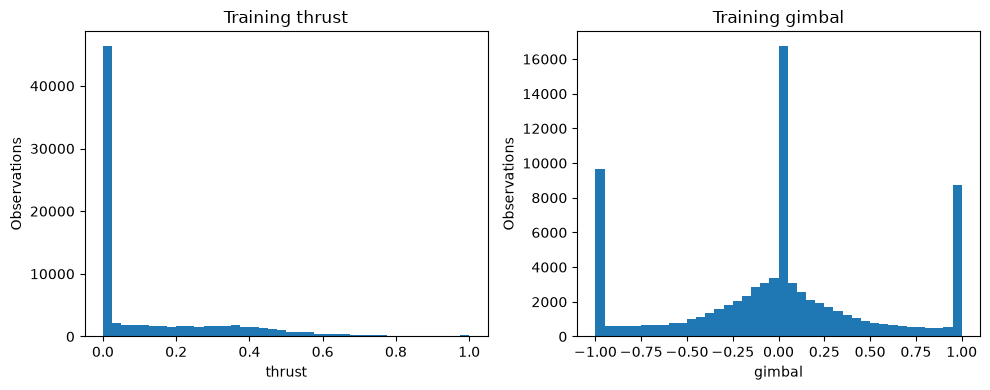

In [6]:
# These are continuous variables so we have to bin them first in order to plot a histogram.
# You can change the number of bins as you like, but 40 is a good starting point.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, target in zip(axes, TARGETS):
    ax.hist(train[target], bins=40)
    ax.set(title=f"Training {target}", xlabel=target, ylabel="Observations")
plt.tight_layout()
plt.show()

#### Interpretation

There is an obvious imbalance here, the expert likes to use low thrust and hardly ever max thrust -> So it'll be hard for our model to learn max thrust behaviour regardless on the architecture. Gimbal looks better but still heavily imbalanced. We can't use class weighting here because there aren't classes, but we can do sampling. Before though, I should train the base model to see it's performance. I'm going to add some tweaks to the base training code though, as I also want to tune the model, so I'm actually making a realistic comparison and not comparing any new models to a weak baseline.

In [7]:
# Data prep & model tuning functions
def tensors(frame):
    x = frame[FEATURES].to_numpy(dtype=np.float32, copy=True)
    y = frame[TARGETS].to_numpy(dtype=np.float32, copy=True)
    return torch.from_numpy(x).to(device), torch.from_numpy(y).to(device) # I added two device calls here, otherwise the model and the data are on different devices and pytorch will error.

train_x, train_y = tensors(train)
val_x, val_y = tensors(val)
test_x, test_y = tensors(test)

# Just some hyperarameters to try, there will be 20 combinations here, so 20 runs.
batch_sizes = [256, 512, 1024, 2048]
learning_rates = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
max_epochs = 200
early_stopping_patience = 10
optimiser = torch.optim.Adam # Don't init the optimiser here, it needs to be initialised with the model parameters each time.
smooth_l1 = nn.SmoothL1Loss() # This is the same as Huber loss, which is less sensitive to outliers than MSE loss.

# This is a wrapper so it works with a later loss function that needs to access the model's outputs directly.
def loss_fn(model, x, y):
    return smooth_l1(model(x), y)

# I'll write a function so I can use it later
def tune_model(model_factory, train_x, train_y, val_x, val_y, optimiser_class, loss_fn, learning_rates, batch_sizes, max_epochs, early_stopping_patience, model_name="BaseModel"):
    """Grid search over learning rate and batch size, with early stopping on the validation loss.

    Returns the model with the lowest validation loss, a table with one row per run (best first),
    and the per-epoch losses for each (learning_rate, batch_size).
    """
    results, histories = [], {}
    overall_best_loss = float("inf")
    overall_best_state = None

    runs_bar = tqdm(total=len(learning_rates) * len(batch_sizes), desc=model_name, unit="run") # Set up the progress bar

    for learning_rate in learning_rates:
        for batch_size in batch_sizes:
            # Use the same seed for every run so that they differ only in their hyperparameters.
            torch.manual_seed(seed)
            model = model_factory().to(device) # Create a new model for each combination of hyperparameters.
            optimiser = optimiser_class(model.parameters(), lr=learning_rate, fused=True) # Fused Adam is faster on GPUs, but not available on all platforms.

            best_val_loss = float("inf")
            best_epoch = 0
            epochs_without_improvement = 0
            history = {"train": [], "val": []}

            # Early stopping usually ends a run well before max_epochs, so this bar often will not fill.
            epochs_bar = tqdm(range(1, max_epochs + 1), desc=f"lr {learning_rate:g}, batch size {batch_size}", unit="epoch", leave=False)
            for epoch in epochs_bar:
                model.train()
                total_loss = torch.zeros((), device=device) # Keep this on the device, calling .item() on every batch is slow.

                # All of the data is already on the device, so indexing a whole batch at once is much
                # faster than a DataLoader, which would fetch the rows one at a time.
                for batch in torch.randperm(len(train_x), device=device).split(batch_size):
                    optimiser.zero_grad()
                    loss = loss_fn(model, train_x[batch], train_y[batch])
                    loss.backward()
                    optimiser.step()
                    total_loss += loss.detach() * len(batch)

                model.eval()
                with torch.no_grad():
                    val_loss = loss_fn(model, val_x, val_y).item()

                history["train"].append(total_loss.item() / len(train_x))
                history["val"].append(val_loss)

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    best_epoch = epoch
                    epochs_without_improvement = 0
                    # Clone the weights from the best epoch, otherwise later epochs would overwrite them.
                    if val_loss < overall_best_loss:
                        overall_best_loss = val_loss
                        overall_best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
                else:
                    epochs_without_improvement += 1
                    if epochs_without_improvement >= early_stopping_patience:
                        break

                epochs_bar.set_postfix(val=f"{val_loss:.5f}", best=f"{best_val_loss:.5f}", patience=f"{epochs_without_improvement}/{early_stopping_patience}")

            epochs_bar.close()

            histories[(learning_rate, batch_size)] = history
            results.append({
                "model": model_name,
                "learning_rate": learning_rate,
                "batch_size": batch_size,
                "best_val_loss": best_val_loss,
                "best_epoch": best_epoch,
                "epochs_run": epoch,
            })
            tqdm.write(f"{model_name} | lr {learning_rate:g}, batch size {batch_size} | best validation loss {best_val_loss:.5f} at epoch {best_epoch} (ran {epoch})")
            runs_bar.update()
            runs_bar.set_postfix(best=f"{overall_best_loss:.5f}")

    runs_bar.close()

    if overall_best_state is None:
        raise RuntimeError("No run produced a finite validation loss.")

    best_model = model_factory().to(device)
    best_model.load_state_dict(overall_best_state)
    best_model.eval()

    results = pd.DataFrame(results).sort_values("best_val_loss", ignore_index=True)
    return best_model, results, histories

In [8]:
from model import create_model

tuned_model, tuning_results, tuning_histories = tune_model(
    model_factory=create_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="BaseModel",
)

BaseModel:   0%|          | 0/20 [00:00<?, ?run/s]

lr 0.0001, batch size 256:   0%|          | 0/200 [00:00<?, ?epoch/s]

BaseModel | lr 0.0001, batch size 256 | best validation loss 0.02115 at epoch 197 (ran 200)


lr 0.0001, batch size 512:   0%|          | 0/200 [00:00<?, ?epoch/s]

BaseModel | lr 0.0001, batch size 512 | best validation loss 0.02172 at epoch 198 (ran 200)


lr 0.0001, batch size 1024:   0%|          | 0/200 [00:00<?, ?epoch/s]

... (31 outputs left out)

lr 0.01, batch size 1024:   0%|          | 0/200 [00:00<?, ?epoch/s]

BaseModel | lr 0.01, batch size 1024 | best validation loss 0.01852 at epoch 42 (ran 52)


lr 0.01, batch size 2048:   0%|          | 0/200 [00:00<?, ?epoch/s]

BaseModel | lr 0.01, batch size 2048 | best validation loss 0.01854 at epoch 48 (ran 58)


In [9]:
print("Tuning results:")
display(tuning_results.head(5))

Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,BaseModel,0.010,1024,0.018524,42,52
1,BaseModel,0.010,2048,0.018538,48,58
2,BaseModel,0.005,1024,0.018806,45,55
3,BaseModel,0.001,2048,0.018858,183,193
4,BaseModel,0.005,2048,0.018914,64,74


In [10]:
# Putting the evaluation code in a function so it can be reused
def evaluate_model(model, test_x, test_y):
    model.eval()
    with torch.no_grad():
        predictions = model(test_x).detach().cpu().numpy()
        
    test_y_cpu = test_y.detach().cpu().numpy()

    errors = np.abs(predictions - test_y_cpu)
    for i, target in enumerate(TARGETS):
        print(f"{target} test MAE: {errors[:, i].mean():.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for i, (ax, target) in enumerate(zip(axes, TARGETS)):
        ax.scatter(test_y_cpu[::10, i], predictions[::10, i], s=3, alpha=0.2)
        ax.set(xlabel="Expert", ylabel="Prediction", title=target)

    plt.tight_layout()
    plt.show()

thrust test MAE: 0.0251
gimbal test MAE: 0.1480


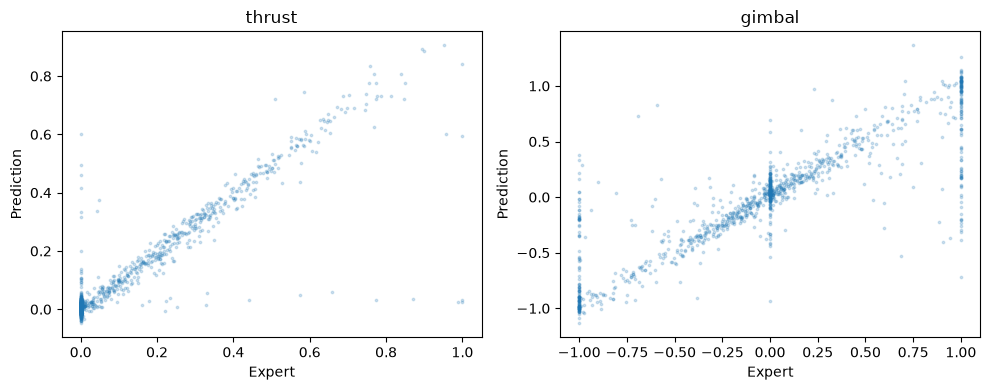

In [11]:
evaluate_model(tuned_model, test_x, test_y)

#### Interpretation

Batch size of 256 is quite slow compared to the others. As the model is very small, most of the time is spent on launching GPU operations, and there is no worry with memory overflow if we increase this. It also looks like the best loss is with a LR of 0.01 and batch size of 1024 with 2028 close behind which is good as training should be fast. For future models, I'll remove the batch size of 256 and 512 and increase the number of epochs so the larger batch sizes converge with a smaller learning rate.

#### Fixing the model output so it runs in the sim

Currently, the output unbounded, as you can see from the above plot which is an issue for the simulator. It only accepts outputs in the specified ranges so it errors with the model I gave you.

A simple fix is to add a sigmoid output to the thrust and a tanh activation to the gimbal output.
- torch.tanh()
- torch.sigmoid()

I don't expect this to really give a better result for the loss but it means it can be run in the simulator now.

In [12]:
batch_sizes = [1024, 2048, 4096] # Also adding a larger batch size to see if it helps with the training speed and stability.
max_epochs = 1000

In [13]:
from fixone import create_model as create_fixed_one_model

tuned_model_fixed_activation, tuning_results, tuning_histories = tune_model(
    model_factory=create_fixed_one_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelWithFixedActivations",
)

ModelWithFixedActivations:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithFixedActivations | lr 0.0001, batch size 1024 | best validation loss 0.02123 at epoch 404 (ran 414)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithFixedActivations | lr 0.0001, batch size 2048 | best validation loss 0.02203 at epoch 522 (ran 532)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithFixedActivations | lr 0.01, batch size 2048 | best validation loss 0.01890 at epoch 32 (ran 42)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithFixedActivations | lr 0.01, batch size 4096 | best validation loss 0.01793 at epoch 76 (ran 86)


In [14]:
print("Tuning results:")
display(tuning_results.head(5))

Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithFixedActivations,0.010,4096,0.017932,76,86
1,ModelWithFixedActivations,0.005,1024,0.018365,64,74
2,ModelWithFixedActivations,0.010,2048,0.018896,32,42
3,ModelWithFixedActivations,0.005,2048,0.018916,78,88
4,ModelWithFixedActivations,0.001,2048,0.019421,171,181


thrust test MAE: 0.0261
gimbal test MAE: 0.1470


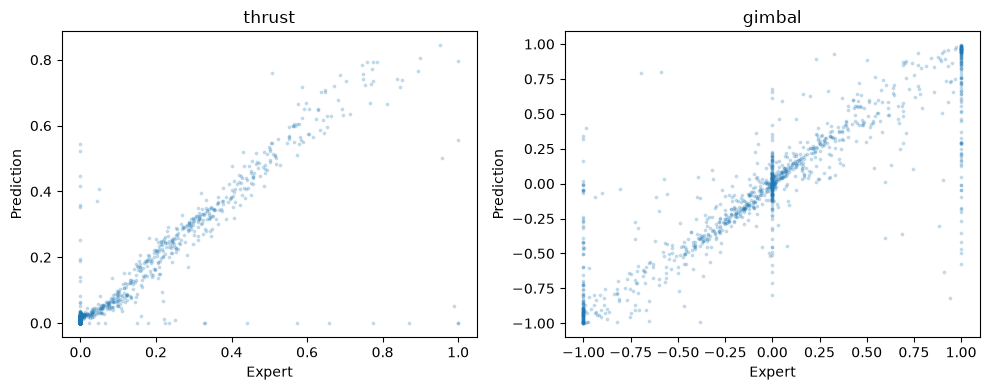

In [15]:
evaluate_model(tuned_model_fixed_activation, test_x, test_y)

#### Intepretation

The thrust error is a bit better here, but the gimbal error is a bit worse. Now we have the bounded outputs though. The higher learning rates are definitely better for a simple model like this and the larger batch size too so we can keep them as they are.

Let's test in the sim.

In [16]:
# Simulator code
from dataclasses import replace

from rocket_closed_loop import evaluate_closed_loop
from rocket_physics import Command
from rocket_runtime import scenario
from rocket_scoring import CONFIG


def simulate(model, scenario_name, *, seed=None):
    model.eval()

    device = next(model.parameters()).device

    def policy(observation):
        with torch.inference_mode():
            x = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)
            output = model(x)

        if not isinstance(output, torch.Tensor) or tuple(output.shape) != (1, 2):
            raise ValueError("The model must return a tensor with shape (1, 2).")

        thrust, gimbal = output[0].tolist()
        return Command(thrust, gimbal)

    if scenario_name == "random_start":
        scenario_name = "demo_descent"
        parameters, initial_state = scenario(scenario_name)
        rng = np.random.default_rng(seed)
        initial_state = replace(
            initial_state,
            x=float(rng.uniform(-40.0, 40.0)),
            y=float(rng.uniform(350.0, 850.0)),
        )
    else:
        parameters, initial_state = scenario(scenario_name)

    result = evaluate_closed_loop(
        policy, initial_state, parameters, scenario_name,
        control_mode="continuous",
    )

    if result["replay"]["status"] == "error":
        raise ValueError(result["termination_reason"])
    return result


In [17]:
# Run a bunch of random simulations to get a good idea about performance
def run_sims(model, n_flights=50, n_plots=6, first_seed=42):

    simulation_results = {
        seed: simulate(model, "random_start", seed=seed)
        for seed in range(first_seed, first_seed + n_flights)
    }

    rows = []
    for seed, result in simulation_results.items():
        scoring = result["scoring"]
        snapshots = result["replay"]["snapshots"]
        # The last state is the touchdown, or wherever the rocket was when time ran out.
        final = snapshots[-1]["state"]
        # Touchdown errors are None if the rocket never made contact.
        errors = scoring["errors"]
        rows.append({
            "Seed": seed,
            "Start x (m)": snapshots[0]["state"]["x"],
            "Start height (m)": snapshots[0]["state"]["y"],
            "Score / 100": scoring["score"],
            "Success": scoring["success"],
            # Mean normalised touchdown error: 0 is perfect, 1 means every limit was reached.
            "Touchdown error": np.mean(list(errors.values())) if errors else np.inf,
            "Final x (m)": final["x"],
            "Final height (m)": final["y"],
            "vx (m/s)": final["vx"],
            "vy (m/s)": final["vy"],
            "Tilt (deg)": np.degrees(final["theta"]),
            "Angular rate (deg/s)": np.degrees(final["omega"]),
            "Fuel left (kg)": final["fuel"],
            "Simulation time (s)": snapshots[-1]["time"],
            "Landing feedback": "; ".join(scoring["reasons"]) or "Safe landing",
        })

    # Best flights first. Failed flights all score 0, so touchdown error ranks those.
    summary = pd.DataFrame(rows).sort_values(
        ["Score / 100", "Touchdown error"], ascending=[False, True], ignore_index=True
    )

    print(f"Flights: {len(summary)}")
    print(f"Mean score: {summary['Score / 100'].mean():.2f} / 100")
    print(f"Landing success: {summary['Success'].sum()}/{len(summary)} ({100 * summary['Success'].mean():.1f}%)")

    # A flight can fail for several reasons, so these counts can add up to more than n_flights.
    reasons = pd.Series(
        [reason for result in simulation_results.values() for reason in result["scoring"]["reasons"]],
        dtype=object,
    )
    if len(reasons):
        display(reasons.value_counts().rename_axis("Failure reason").to_frame("Flights"))

    # Pick flights evenly spaced through the ranking, including the best and the worst.
    selected = summary.iloc[np.linspace(0, len(summary) - 1, min(n_plots, len(summary))).round().astype(int)]
    overview = ["Seed", "Start x (m)", "Start height (m)", "Score / 100", "Touchdown error", "Simulation time (s)", "Landing feedback"]
    final_state = ["Seed", "Final x (m)", "Final height (m)", "vx (m/s)", "vy (m/s)", "Tilt (deg)", "Angular rate (deg/s)", "Fuel left (kg)"]
    display(selected[overview].round(2))

    print(
        f"Final state. Safe landing limits: |vx| <= {CONFIG.max_horizontal_speed} m/s, "
        f"-{CONFIG.max_descent} <= vy <= 0 m/s, |tilt| <= {np.degrees(CONFIG.max_tilt):.1f} deg, "
        f"|angular rate| <= {np.degrees(CONFIG.max_angular_rate):.1f} deg/s"
    )
    display(selected[final_state].round(2))

    n_cols = 3
    n_rows = int(np.ceil(len(selected) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), sharex=True, sharey=True, squeeze=False)

    for ax, (rank, row) in zip(axes.flat, selected.iterrows()):
        states = [frame["state"] for frame in simulation_results[row["Seed"]]["replay"]["snapshots"]]
        ax.plot([state["x"] for state in states], [state["y"] for state in states], label="Flight path")
        ax.plot(states[0]["x"], states[0]["y"], "o", color="tab:blue", label="Start")
        ax.plot([CONFIG.pad_left, CONFIG.pad_right], [CONFIG.pad_height] * 2, color="black", linewidth=3, label="Landing pad")
        outcome = "landed" if row["Success"] else "failed"
        ax.set_title(f"Rank {rank + 1}/{len(summary)} | seed {row['Seed']} | {outcome}, {row['Score / 100']:.1f}", fontsize=10)

    # Hide any unused axes, and only label the outer edges as the axes are shared.
    for ax in axes.flat[len(selected):]:
        ax.set_visible(False)
    fig.supxlabel("Horizontal position (m)")
    fig.supylabel("Centre-of-mass height (m)")
    axes[0, 0].legend()

    plt.tight_layout()
    plt.show()

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
no contact,33
vertical velocity outside limits,17
angular velocity outside limits,14
horizontal velocity outside limits,13
tilt outside limits,10
contact outside concrete pad,3
foot outside concrete pad,3


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,68,-1.25,774.16,0.0,0.64,17.72,vertical velocity outside limits; tilt outside...
10,91,-17.35,805.13,0.0,0.81,19.62,vertical velocity outside limits; horizontal v...
20,47,19.34,726.83,0.0,inf,30.00,no contact
29,59,7.02,763.03,0.0,inf,30.00,no contact
39,75,-22.94,426.56,0.0,inf,30.00,no contact
49,90,-10.21,690.95,0.0,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,68,8.78,19.84,0.02,-11.66,7.87,-1.68,8826.99
10,91,0.19,19.49,-1.86,-7.08,4.09,-5.62,8516.11
20,47,29.10,260.71,2.19,42.66,-0.57,0.08,6557.71
29,59,47.63,232.06,3.29,39.43,-0.77,-0.15,6604.97
39,75,88.74,607.82,3.48,64.13,1.25,0.67,6243.78
49,90,68.20,394.18,3.64,50.94,-0.33,0.21,6452.17


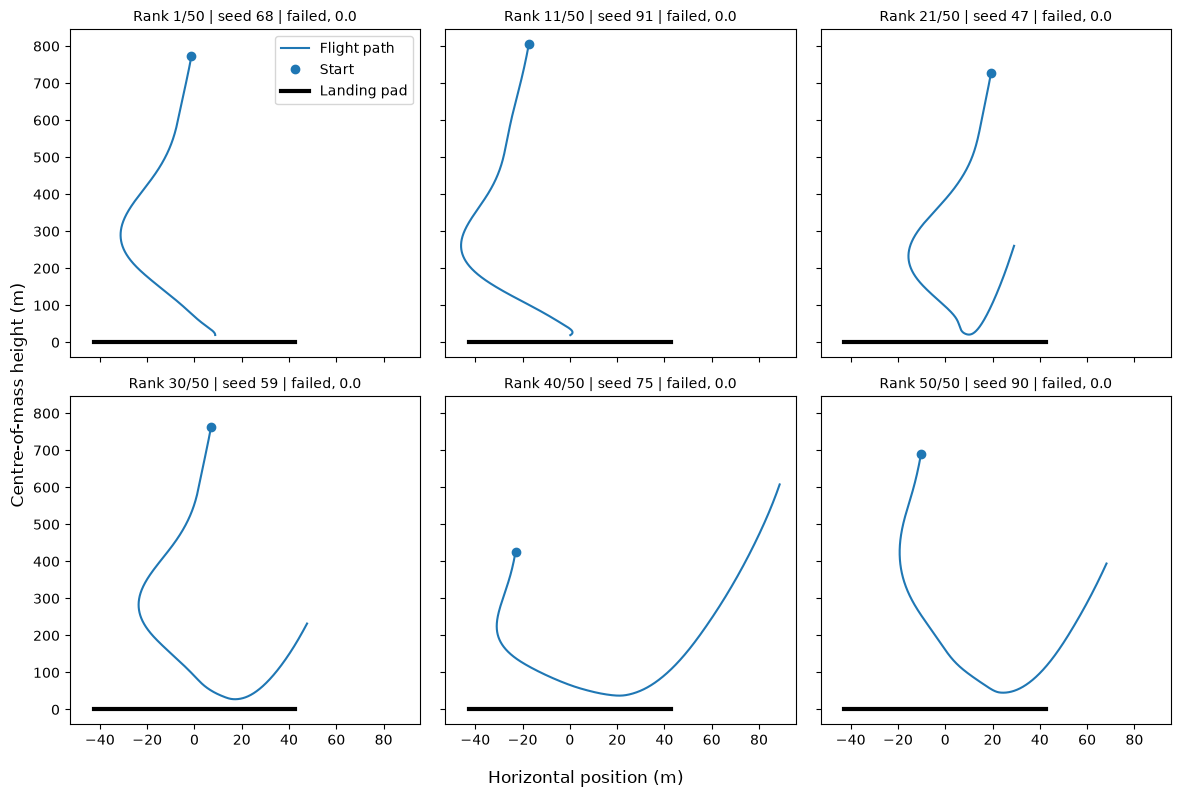

In [18]:
run_sims(tuned_model_fixed_activation)

#### Interpretation

Quite a few of these fly off instead of crashing or landing. I think it is because the simulator needs an exact value of 0.0 in order to switch off the engine. 
A better loss function in that case will likely be some sort of clamped output but done in a way that it doesn't influence the gradients.

Something like `clamped = torch.clamp(x, 0, 1)`. However this isn't ideal because it is flat outside of this range and therefore it has no gradient. So instead of just this I'll add a line like this:

`return x + (clamped - x).detach()`

This means in the forward pass it returns clamped, but in the backwards pass the bracket is nothing and therefore the gradient is just x. Obviously this isn't ideal because it's approximate but it allows the model to return 0 now.

There is also an alternative to add a 3rd output or a feature that chooses to switch the engine on or off. I will test both. First the clamping.

In [19]:
from clamped import create_model as create_clamped_model

tuned_model_clamped, tuning_results, tuning_histories = tune_model(
    model_factory=create_clamped_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelWithClampedThrustActivation",
)

ModelWithClampedThrustActivation:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithClampedThrustActivation | lr 0.0001, batch size 1024 | best validation loss 0.02101 at epoch 432 (ran 442)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithClampedThrustActivation | lr 0.0001, batch size 2048 | best validation loss 0.01978 at epoch 880 (ran 890)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithClampedThrustActivation | lr 0.01, batch size 2048 | best validation loss 0.01830 at epoch 33 (ran 43)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithClampedThrustActivation | lr 0.01, batch size 4096 | best validation loss 0.01741 at epoch 85 (ran 95)


In [20]:
print("Tuning results:")
display(tuning_results.head(5))

Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithClampedThrustActivation,0.010,4096,0.017414,85,95
1,ModelWithClampedThrustActivation,0.010,1024,0.017709,68,78
2,ModelWithClampedThrustActivation,0.005,2048,0.018170,55,65
3,ModelWithClampedThrustActivation,0.010,2048,0.018305,33,43
4,ModelWithClampedThrustActivation,0.005,1024,0.018367,45,55


thrust test MAE: 0.0214
gimbal test MAE: 0.1472


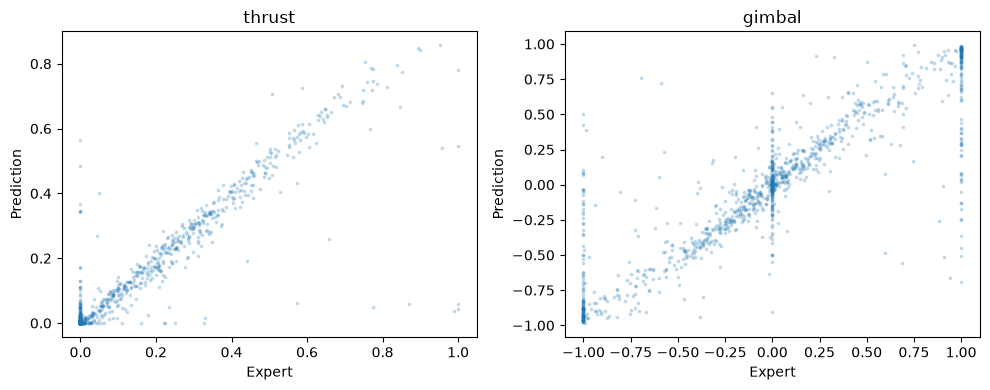

In [21]:
evaluate_model(tuned_model_clamped, test_x, test_y)

Flights: 50
Mean score: 1.57 / 100
Landing success: 1/50 (2.0%)


,Flights
Failure reason,
vertical velocity outside limits,37
angular velocity outside limits,32
horizontal velocity outside limits,20
tilt outside limits,16
no contact,10
foot outside concrete pad,2


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,81,-5.27,455.81,78.42,0.36,14.58,Safe landing
10,64,35.48,611.67,0.00,0.65,13.86,vertical velocity outside limits; horizontal v...
20,71,-19.73,613.77,0.00,0.77,11.33,vertical velocity outside limits; horizontal v...
29,51,35.40,503.57,0.00,0.85,12.31,vertical velocity outside limits; tilt outside...
39,76,24.51,842.76,0.00,1.00,13.84,foot outside concrete pad; vertical velocity o...
49,89,6.06,734.97,0.00,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,81,-28.06,18.73,-1.01,-0.50,0.15,0.14,9070.16
10,64,3.21,18.97,-2.43,-11.54,-2.41,-1.20,9334.22
20,71,4.07,18.90,-4.09,-13.87,2.76,-4.89,9686.85
29,51,-21.54,19.30,0.84,-10.98,-5.32,5.22,9521.78
39,76,36.80,19.70,-2.33,-14.33,8.28,-4.81,9380.39
49,89,50.14,64.17,3.41,4.95,-0.76,-0.04,7054.95


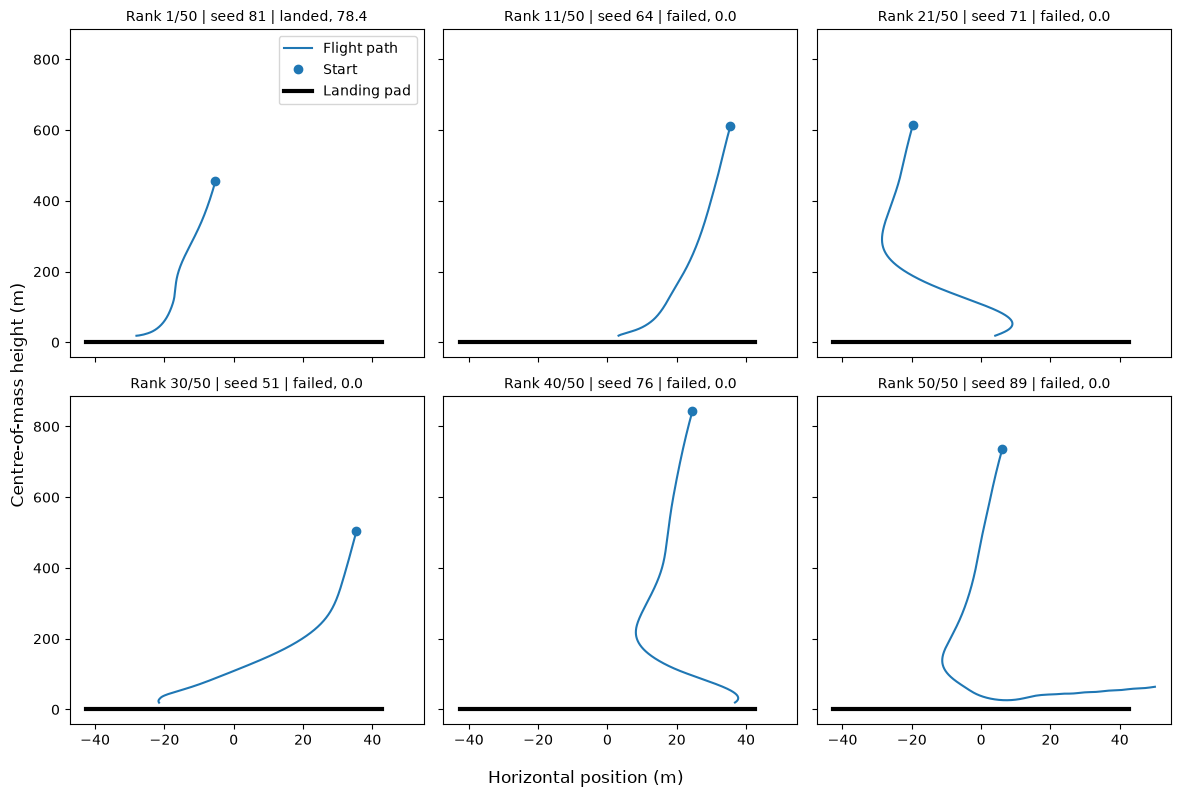

In [22]:
run_sims(tuned_model_clamped)

Well that's a win, one landing successful, lets see if the thrust toggle is successful or not. One thing that is interesting is if the toggle is added is we can also adjust the loss to have a classification aspect - more on that later.


In [23]:
from thrust_toggle import create_model as create_thrust_toggle_model

tuned_model_thrust_toggle, tuning_results, tuning_histories = tune_model(
    model_factory=create_thrust_toggle_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelWithThrustToggleActivation",
)

ModelWithThrustToggleActivation:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivation | lr 0.0001, batch size 1024 | best validation loss 0.03891 at epoch 32 (ran 42)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivation | lr 0.0001, batch size 2048 | best validation loss 0.03900 at epoch 59 (ran 69)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivation | lr 0.01, batch size 2048 | best validation loss 0.03220 at epoch 48 (ran 58)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivation | lr 0.01, batch size 4096 | best validation loss 0.03101 at epoch 64 (ran 74)


In [24]:
print("Tuning results:")
display(tuning_results.head(5))

Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithThrustToggleActivation,0.005,4096,0.024893,104,114
1,ModelWithThrustToggleActivation,0.010,1024,0.027927,42,52
2,ModelWithThrustToggleActivation,0.005,2048,0.028825,49,59
3,ModelWithThrustToggleActivation,0.005,1024,0.028839,22,32
4,ModelWithThrustToggleActivation,0.001,1024,0.030058,101,111


thrust test MAE: 0.0825
gimbal test MAE: 0.1583


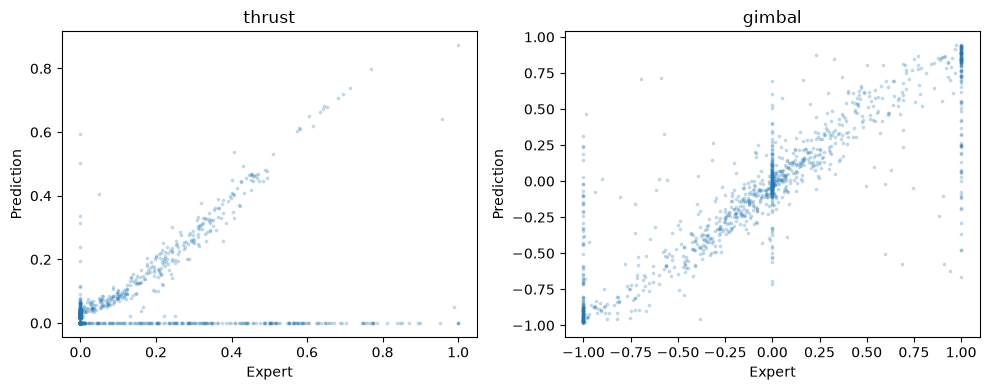

In [25]:
evaluate_model(tuned_model_thrust_toggle, test_x, test_y)

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
vertical velocity outside limits,50
tilt outside limits,49
horizontal velocity outside limits,44
angular velocity outside limits,9
contact outside concrete pad,6
foot outside concrete pad,6


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,76,24.51,842.76,0.0,0.62,10.35,vertical velocity outside limits; horizontal v...
10,57,14.73,584.16,0.0,0.66,7.38,vertical velocity outside limits; horizontal v...
20,82,39.81,777.39,0.0,0.73,9.53,vertical velocity outside limits; horizontal v...
29,73,-0.59,501.68,0.0,0.78,6.73,vertical velocity outside limits; horizontal v...
39,85,-36.45,585.88,0.0,0.84,9.84,vertical velocity outside limits; horizontal v...
49,60,-14.06,363.57,0.0,0.95,5.71,vertical velocity outside limits; horizontal v...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,76,-0.50,19.23,-3.44,-88.40,8.72,-0.06,10985.18
10,57,0.62,19.05,-2.24,-87.58,8.04,-0.44,11322.51
20,82,18.86,19.15,-2.94,-89.30,8.26,0.06,11095.01
29,73,-14.86,19.19,-2.26,-85.02,9.43,-1.08,11353.30
39,85,0.60,20.19,9.68,-70.51,21.34,7.29,10699.15
49,60,-19.66,20.05,4.60,-60.88,-20.70,8.18,11123.70


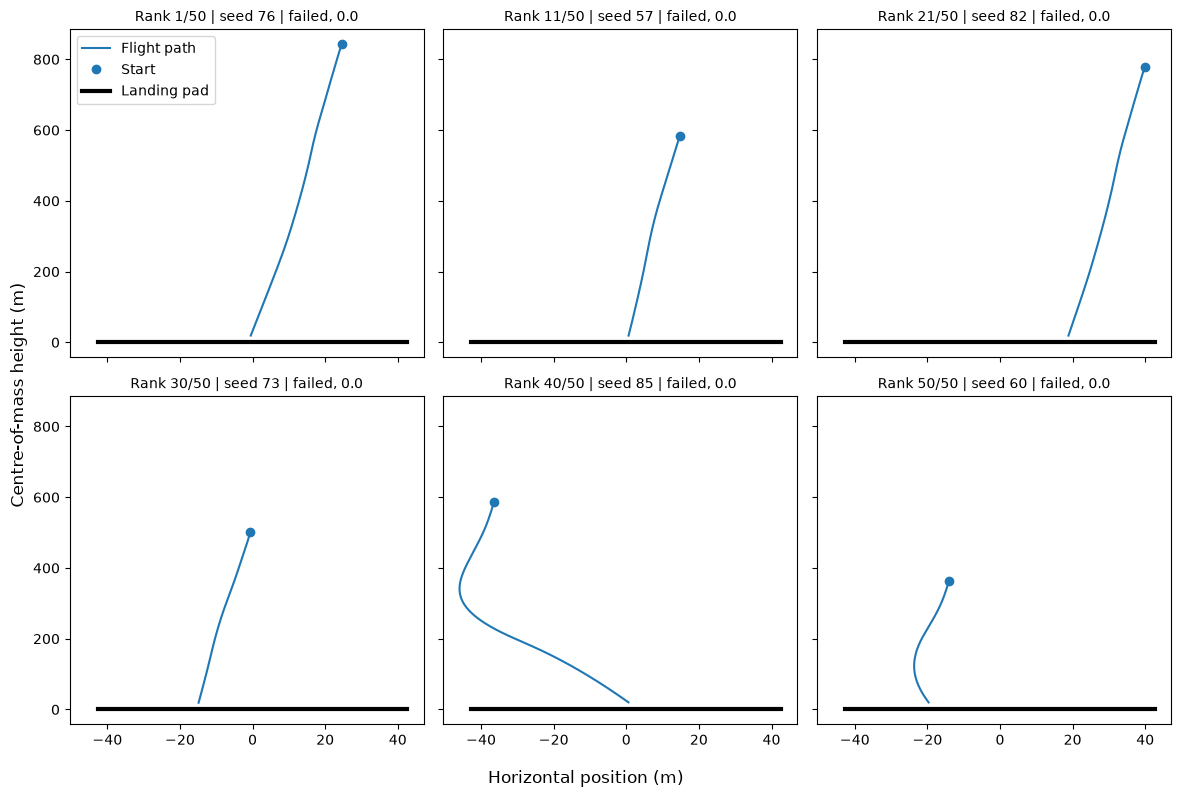

In [26]:
run_sims(tuned_model_thrust_toggle)

The results are identical, now onto the classification objective in the loss function.

So at the moment I use a smooth L1 loss but with the throttle toggle I can also add a BCE loss to that component. In some sort of psuedo code it looks something like this:

```psuedocode
If y > 0 then throttle was on, assign this 1, otherwise 0.
and if prediction > 0 then assign the prediction to 1, otherwise 0
Penalise the difference between these with BCE.
Add this penalty to the original one.
```

In [27]:
def mixed_loss(model, x, y, alpha=0.08):
    model(x)
    on = (y[:, 0] > 0).float()
    gate_loss = nn.functional.binary_cross_entropy_with_logits(model.on_logit, on)
    throttle_loss = (nn.functional.smooth_l1_loss(model.throttle, y[:, 0], reduction="none") * on).sum() / on.sum().clamp_min(1.0)  # Avoid division by zero if no samples are on
    gimbal_loss = nn.functional.smooth_l1_loss(model.gimbal, y[:, 1])
    return alpha * gate_loss + throttle_loss + gimbal_loss

In [28]:
tuned_model_thrust_toggle_new_loss, tuning_results, tuning_histories = tune_model(
    model_factory=create_thrust_toggle_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=mixed_loss,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelWithThrustToggleActivationNewLoss",
)

ModelWithThrustToggleActivationNewLoss:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivationNewLoss | lr 0.0001, batch size 1024 | best validation loss 0.05003 at epoch 434 (ran 444)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivationNewLoss | lr 0.0001, batch size 2048 | best validation loss 0.04948 at epoch 735 (ran 745)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivationNewLoss | lr 0.01, batch size 2048 | best validation loss 0.04395 at epoch 42 (ran 52)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelWithThrustToggleActivationNewLoss | lr 0.01, batch size 4096 | best validation loss 0.04353 at epoch 93 (ran 103)


Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelWithThrustToggleActivationNewLoss,0.010,1024,0.039477,99,109
1,ModelWithThrustToggleActivationNewLoss,0.005,2048,0.042782,88,98
2,ModelWithThrustToggleActivationNewLoss,0.010,4096,0.043526,93,103
3,ModelWithThrustToggleActivationNewLoss,0.010,2048,0.043952,42,52
4,ModelWithThrustToggleActivationNewLoss,0.005,1024,0.044356,45,55


thrust test MAE: 0.0234
gimbal test MAE: 0.1441


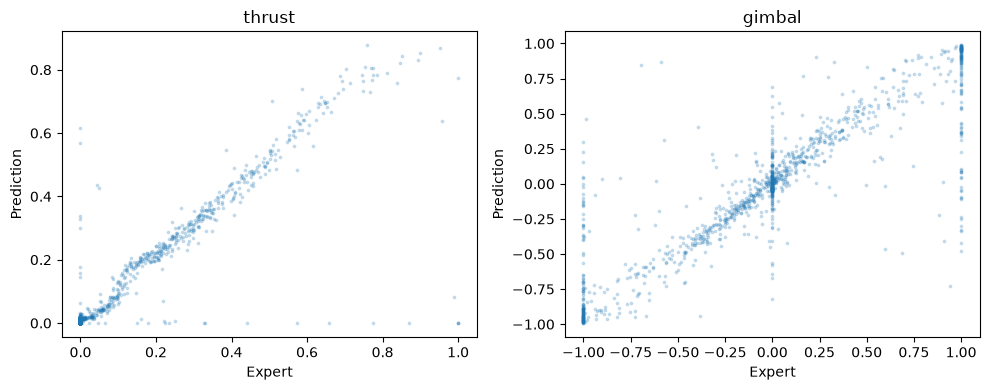

In [29]:
print("Tuning results:")
display(tuning_results.head(5))

evaluate_model(tuned_model_thrust_toggle_new_loss, test_x, test_y)

Flights: 50
Mean score: 1.86 / 100
Landing success: 1/50 (2.0%)


,Flights
Failure reason,
vertical velocity outside limits,47
horizontal velocity outside limits,42
foot outside concrete pad,29
contact outside concrete pad,17
angular velocity outside limits,10
tilt outside limits,2


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,63,4.81,846.13,92.95,0.17,27.82,Safe landing
10,56,18.09,358.45,0.00,0.58,13.33,vertical velocity outside limits; horizontal v...
20,78,-6.49,807.57,0.00,0.68,22.46,contact outside concrete pad; foot outside con...
29,88,-23.50,701.59,0.00,0.73,18.02,contact outside concrete pad; foot outside con...
39,85,-36.45,585.88,0.00,0.80,7.80,vertical velocity outside limits; horizontal v...
49,64,35.48,611.67,0.00,1.00,16.64,foot outside concrete pad; vertical velocity o...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,63,6.54,19.32,0.32,-1.30,0.06,-0.00,7412.20
10,56,-21.56,18.64,-2.31,-6.73,-0.17,-0.43,9312.82
20,78,63.36,19.11,2.98,-4.53,-0.70,-0.45,8139.86
29,88,67.31,19.09,6.01,-8.46,-2.20,0.24,8771.19
39,85,-18.91,18.49,11.98,-37.43,1.78,7.29,10528.43
49,64,-47.61,19.36,-4.32,-15.30,-4.48,-3.82,9028.45


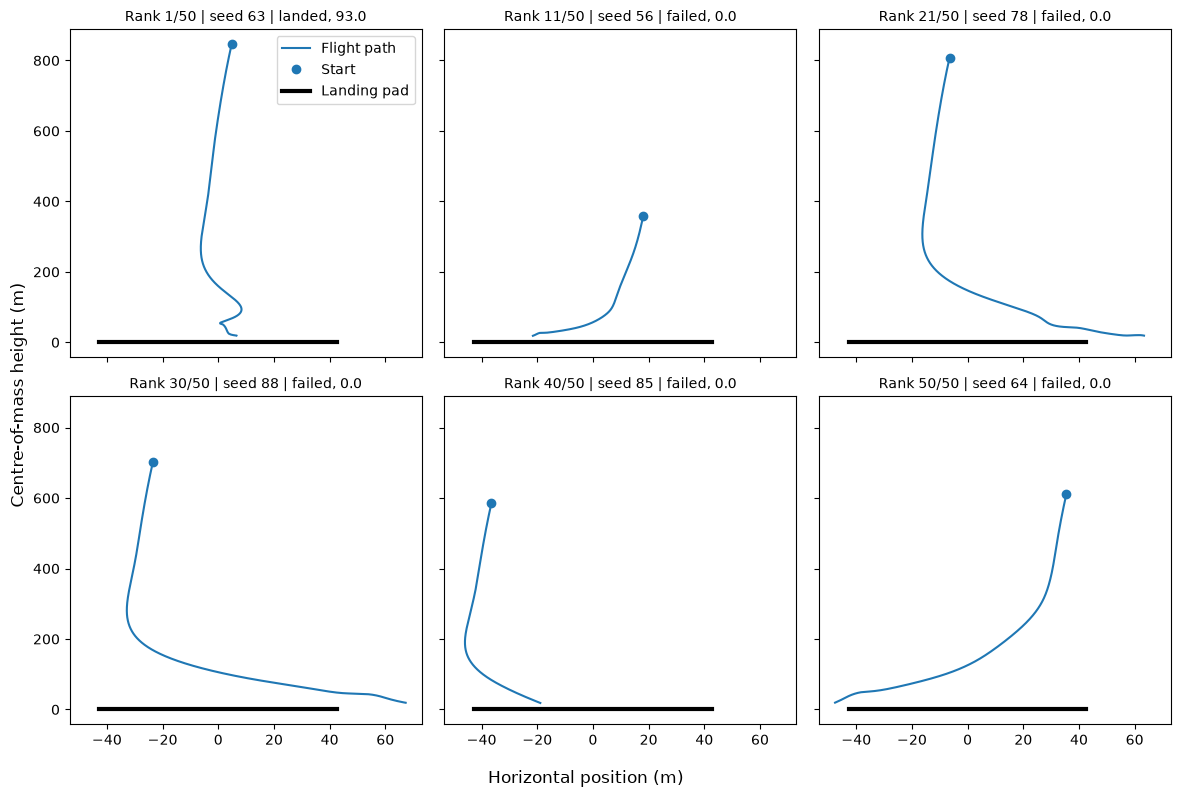

In [30]:
run_sims(tuned_model_thrust_toggle_new_loss)

#### Interpretation

Updating the loss function definitely improved the model, but as it's another thing to tune I will just use the clamped one going forward and then come back to it if that seems limited.

Next, I want to address the balance in the data. By binning the data I can sample uniformly from the bins, the idea is that 

In [50]:
# This divides the numerical range into bins and samples uniformly from each bin, so that the sampled data is more balanced across the range of the target variables.
def balanced_sample(frame, n_total, targets=TARGETS, n_bins=10, seed=0):
    """Sample rows evenly across a grid of bins, with one dimension per target.

    n_bins is the number of bins per target: one int for all targets, or a list with one per target.
    Returns exactly n_total rows. Cells with too few rows are oversampled, so rows can be duplicated.
    """
    if isinstance(n_bins, int):
        n_bins = [n_bins] * len(targets)
    rng = np.random.default_rng(seed)

    # Give every row a bin number for each target. Together these are its cell in the grid.
    grid = []
    for target, bins in zip(targets, n_bins, strict=True):
        codes = pd.cut(frame[target], bins=bins, labels=False)
        if target == "thrust":
            # Exactly 0 is engine off, but 0.00001 is on at minimum thrust, so off gets its own bin.
            codes = codes.mask(frame[target] == 0, -1)
        grid.append(codes.rename(f"{target}_bin"))

    # The row positions in each occupied cell. Empty cells have nothing to sample, so they are skipped.
    cells = list(frame.groupby(grid).indices.values())
    per_cell, remainder = divmod(n_total, len(cells))
    if per_cell == 0:
        raise ValueError(f"n_total must be at least {len(cells)}, the number of occupied cells.")

    # If n_total does not divide evenly, randomly chosen cells get one extra row each.
    sizes = np.full(len(cells), per_cell)
    sizes[rng.permutation(len(cells))[:remainder]] += 1

    # Rows are only repeated when a cell has fewer of them than it needs. Repeats are spread evenly:
    # every row is used size // len(rows) times, and a random selection of rows is used once more.
    chosen = []
    for rows, size in zip(cells, sizes):
        repeats, extra = divmod(size, len(rows))
        chosen.append(np.tile(rows, repeats))
        chosen.append(rng.choice(rows, size=extra, replace=False))

    # Shuffle because the cells should not be in any particular order.
    return frame.iloc[rng.permutation(np.concatenate(chosen))]

# Only the training data is balanced, so that validation and test still match real flights.
balanced_train = balanced_sample(train, n_total=80_000)
balanced_x, balanced_y = tensors(balanced_train)

In [51]:
tuned_model_balanced, tuning_results, tuning_histories = tune_model(
    model_factory=create_clamped_model,
    train_x=balanced_x,
    train_y=balanced_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelClampedWithBalancedTrainingData",
)

ModelClampedWithBalancedTrainingData:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 1024 | best validation loss 0.04662 at epoch 44 (ran 54)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 2048 | best validation loss 0.04629 at epoch 79 (ran 89)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 2048 | best validation loss 0.03188 at epoch 41 (ran 51)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 4096 | best validation loss 0.03487 at epoch 24 (ran 34)


Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelClampedWithBalancedTrainingData,0.010,2048,0.031881,41,51
1,ModelClampedWithBalancedTrainingData,0.010,1024,0.033839,17,27
2,ModelClampedWithBalancedTrainingData,0.010,4096,0.034874,24,34
3,ModelClampedWithBalancedTrainingData,0.005,2048,0.036353,41,51
4,ModelClampedWithBalancedTrainingData,0.005,4096,0.037040,36,46


thrust test MAE: 0.0920
gimbal test MAE: 0.2170


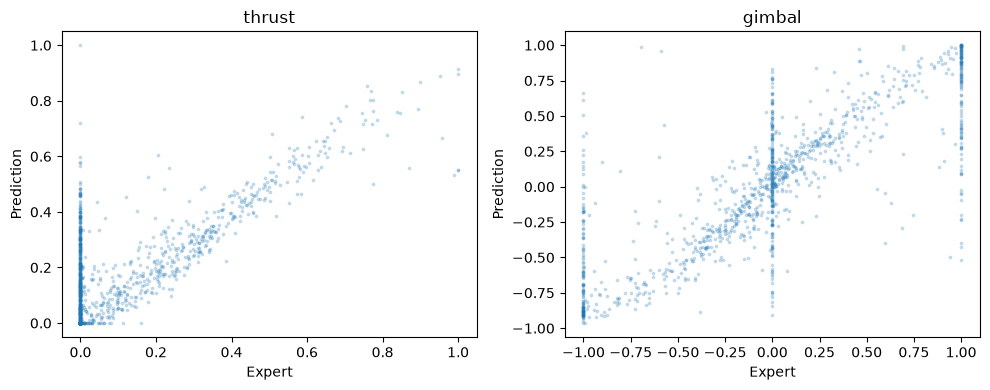

In [52]:
print("Tuning results:")
display(tuning_results.head(5))

evaluate_model(tuned_model_balanced, test_x, test_y)

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
no contact,27
vertical velocity outside limits,23
angular velocity outside limits,22
horizontal velocity outside limits,21
tilt outside limits,20
foot outside concrete pad,15
contact outside concrete pad,11
hull or invalid first contact,1


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,72,27.03,353.34,0.0,0.45,8.77,vertical velocity outside limits
10,52,9.26,637.11,0.0,1.00,18.65,contact outside concrete pad; foot outside con...
20,84,18.57,800.10,0.0,1.00,20.24,foot outside concrete pad; vertical velocity o...
29,51,35.40,503.57,0.0,inf,30.00,no contact
39,74,31.55,610.36,0.0,inf,30.00,no contact
49,91,-17.35,805.13,0.0,inf,30.00,no contact


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,72,9.02,18.59,-0.67,-9.55,1.24,0.39,9959.07
10,52,51.70,16.42,14.09,-34.82,63.45,11.15,8980.92
20,84,28.03,19.79,9.17,-33.27,43.91,8.08,8775.83
29,51,68.49,109.50,-13.33,-18.96,14.34,-11.62,7245.33
39,74,96.96,158.72,17.49,13.34,30.11,19.26,6702.29
49,91,9.06,58.75,15.47,-11.99,18.45,15.64,7240.96


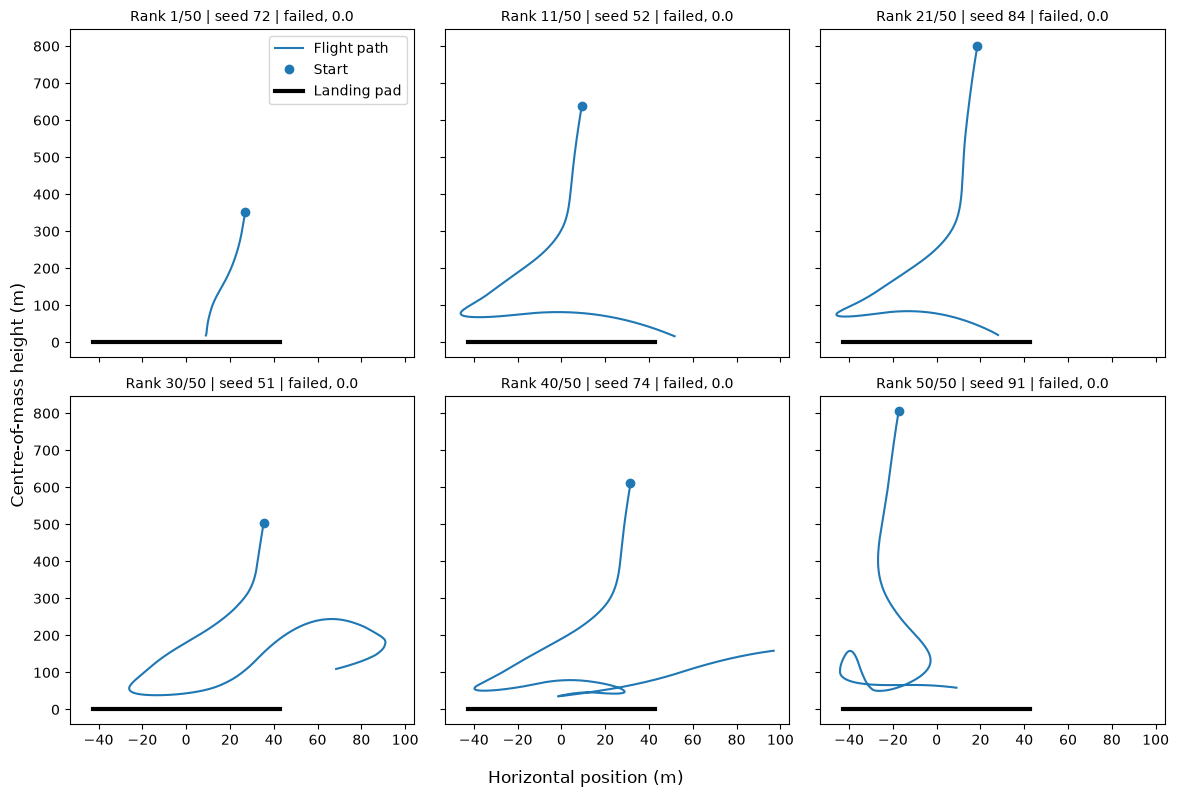

In [53]:
run_sims(tuned_model_balanced)

#### Interpretation

Not good so I will scrap that for now. There is probably some configuration that is better but for now I will go to improving the model and not the data quality.

The next thing I think I shall test is with the previous thrust and gimbal. I believe that the model is maybe just learning the relationship between the current thrust and previous one so I will remove that from the features and see. Again with both the clamped and the thrust feature.

In [60]:
from remove_past_features import create_model as create_remove_past_features_model

tuned_model_balanced, tuning_results, tuning_histories = tune_model(
    model_factory=create_remove_past_features_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelClampedWithBalancedTrainingData",
)

ModelClampedWithBalancedTrainingData:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 1024 | best validation loss 0.03480 at epoch 395 (ran 405)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 2048 | best validation loss 0.03554 at epoch 502 (ran 512)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 2048 | best validation loss 0.02863 at epoch 146 (ran 156)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 4096 | best validation loss 0.03075 at epoch 44 (ran 54)


Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelClampedWithBalancedTrainingData,0.010,2048,0.028626,146,156
1,ModelClampedWithBalancedTrainingData,0.001,2048,0.030243,260,270


thrust test MAE: 0.0592
gimbal test MAE: 0.2396


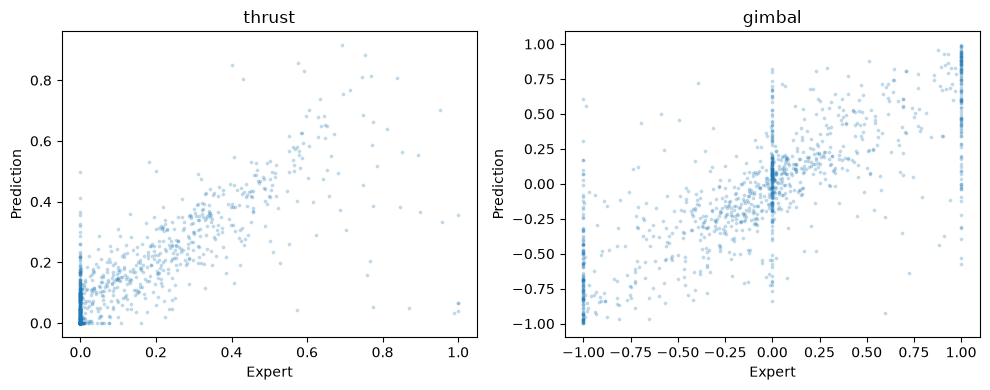

Flights: 50
Mean score: 33.70 / 100
Landing success: 18/50 (36.0%)


,Flights
Failure reason,
vertical velocity outside limits,30
angular velocity outside limits,22
tilt outside limits,10
horizontal velocity outside limits,2


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,86,9.24,437.68,99.05,0.08,12.61,Safe landing
10,47,19.34,726.83,94.56,0.18,15.32,Safe landing
20,59,7.02,763.03,0.00,0.35,15.34,vertical velocity outside limits
29,78,-6.49,807.57,0.00,0.51,15.78,vertical velocity outside limits
39,49,-10.97,646.61,0.00,0.72,14.13,vertical velocity outside limits; angular velo...
49,65,-36.21,609.11,0.00,0.92,14.18,vertical velocity outside limits; horizontal v...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,86,2.18,18.63,0.27,-0.32,0.13,0.04,9326.81
10,47,1.59,18.74,-0.39,-1.03,-0.11,0.46,9012.23
20,59,8.60,18.78,0.13,-3.58,0.45,-0.58,9047.42
29,78,10.03,18.96,0.17,-4.51,1.53,-1.53,9010.33
39,49,11.95,19.16,0.53,-6.43,3.48,-2.35,9232.60
49,65,17.61,19.62,1.52,-8.67,7.20,-2.90,9257.75


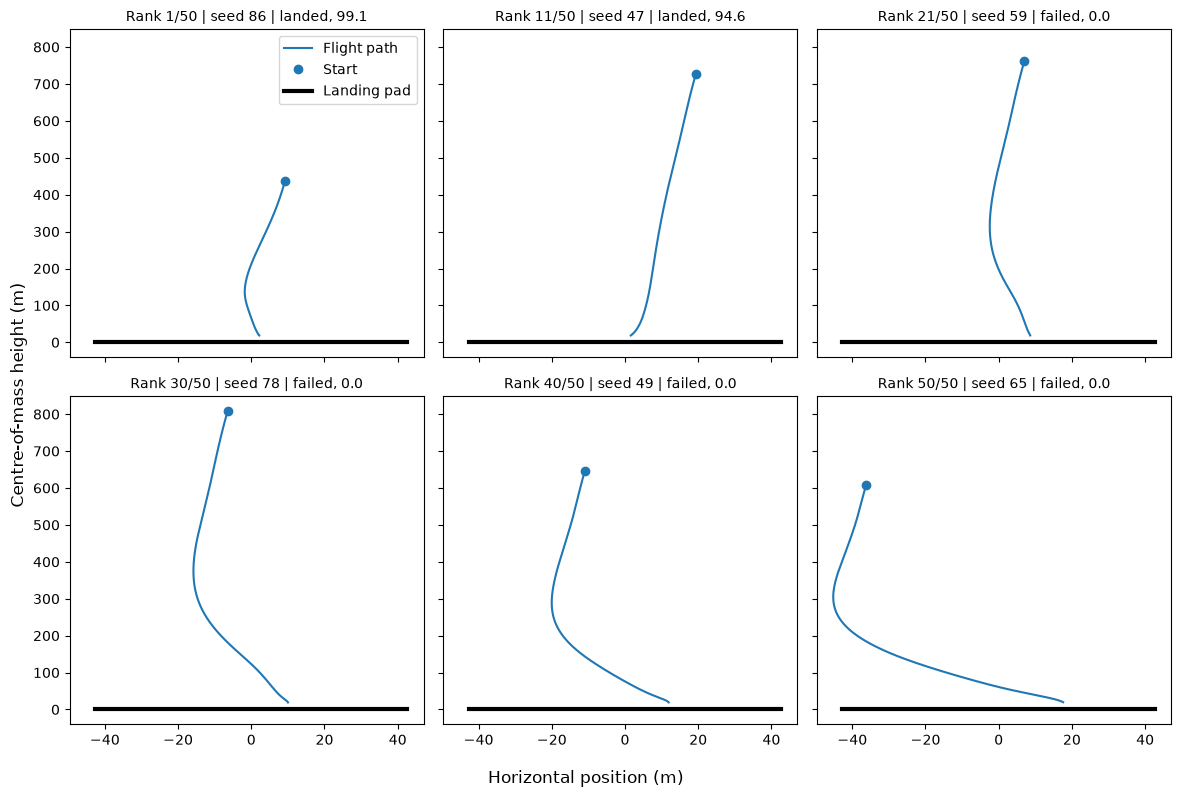

In [61]:
print("Tuning results:")
display(tuning_results.head(2))

evaluate_model(tuned_model_balanced, test_x, test_y)

run_sims(tuned_model_balanced)

#### Interpretation

This is significantly better on the landing, but worse on the agreement. Next step is to just try to add another layer to increase the model complexity, but I believe this might just better the agreement and not the landing performance.

In [64]:
from layers_and_dropout import create_model as create_layers_and_dropout_model

tuned_model_balanced, tuning_results, tuning_histories = tune_model(
    model_factory=create_layers_and_dropout_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelClampedWithBalancedTrainingData",
)

ModelClampedWithBalancedTrainingData:   0%|          | 0/15 [00:00<?, ?run/s]

lr 0.0001, batch size 1024:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 1024 | best validation loss 0.03023 at epoch 355 (ran 365)


lr 0.0001, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.0001, batch size 2048 | best validation loss 0.02909 at epoch 600 (ran 610)


lr 0.0001, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

... (21 outputs left out)

lr 0.01, batch size 2048:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 2048 | best validation loss 0.02721 at epoch 54 (ran 64)


lr 0.01, batch size 4096:   0%|          | 0/1000 [00:00<?, ?epoch/s]

ModelClampedWithBalancedTrainingData | lr 0.01, batch size 4096 | best validation loss 0.02781 at epoch 37 (ran 47)


Tuning results:


,model,learning_rate,batch_size,best_val_loss,best_epoch,epochs_run
0,ModelClampedWithBalancedTrainingData,0.010,2048,0.027207,54,64
1,ModelClampedWithBalancedTrainingData,0.005,2048,0.027255,77,87


thrust test MAE: 0.0592
gimbal test MAE: 0.2245


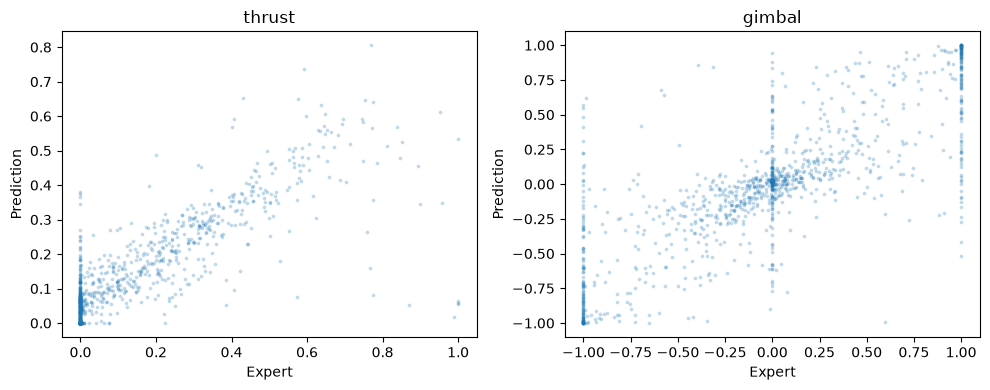

Flights: 50
Mean score: 0.00 / 100
Landing success: 0/50 (0.0%)


,Flights
Failure reason,
vertical velocity outside limits,50
horizontal velocity outside limits,22
tilt outside limits,9


,Seed,Start x (m),Start height (m),Score / 100,Touchdown error,Simulation time (s),Landing feedback
0,57,14.73,584.16,0.0,0.25,12.70,vertical velocity outside limits
10,86,9.24,437.68,0.0,0.29,10.56,vertical velocity outside limits
20,84,18.57,800.10,0.0,0.41,14.47,vertical velocity outside limits
29,61,-10.05,735.97,0.0,0.61,13.98,vertical velocity outside limits; horizontal v...
39,82,39.81,777.39,0.0,0.70,15.09,vertical velocity outside limits; horizontal v...
49,65,-36.21,609.11,0.0,0.80,13.36,vertical velocity outside limits; horizontal v...


Final state. Safe landing limits: |vx| <= 1.5 m/s, -3.0 <= vy <= 0 m/s, |tilt| <= 4.0 deg, |angular rate| <= 2.0 deg/s


,Seed,Final x (m),Final height (m),vx (m/s),vy (m/s),Tilt (deg),Angular rate (deg/s),Fuel left (kg)
0,57,1.80,18.59,0.08,-7.48,0.09,-0.21,9428.09
10,86,-0.93,18.54,0.34,-7.74,0.33,-0.23,9700.73
20,84,-1.98,18.84,-0.85,-8.83,-1.31,-0.20,9238.66
29,61,6.77,18.94,2.25,-8.84,2.07,0.58,9297.64
39,82,-10.55,19.28,-1.88,-6.23,-4.13,-0.26,9125.04
49,65,21.08,20.06,4.61,-13.29,12.20,-0.52,9430.42


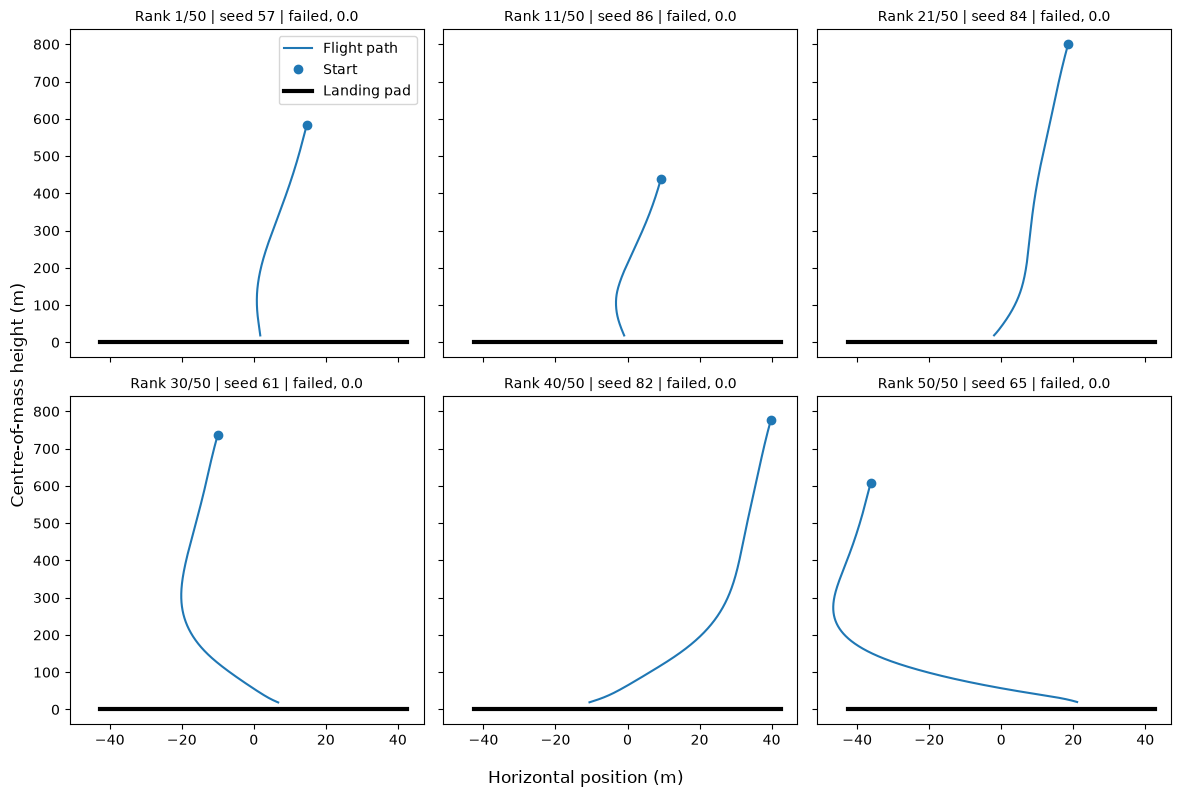

In [65]:
print("Tuning results:")
display(tuning_results.head(2))

evaluate_model(tuned_model_balanced, test_x, test_y)

run_sims(tuned_model_balanced)

#### Interpretation

As expected the agreement is better but landing performance is worse. The plots look very similar though so I think it's potentially overfitting to the loss instead of the actual task. Reverting this change.

The next step is to create some more informative features, ideally we want to do this outside of the model, which I will do for training. Unfortunately for the online submission it will have to be done in the model so we don't benefit from the batching data but given that its a step by step simulation that's not really an issue.

In [ ]:
# The first feature I'm going to create is acceleration, for x, y and rotation. The simulator only gives the model the current observation,
# so instead of using the difference from the previous velocity, the model computes it from the forces using the simulator's equations.
from acceleration_features import create_model as create_acceleration_model

tuned_model_acceleration, tuning_results, tuning_histories = tune_model(
    model_factory=create_acceleration_model,
    train_x=train_x,
    train_y=train_y,
    val_x=val_x,
    val_y=val_y,
    optimiser_class=optimiser,
    loss_fn=loss_fn,
    learning_rates=learning_rates,
    batch_sizes=batch_sizes,
    max_epochs=max_epochs,
    early_stopping_patience=early_stopping_patience,
    model_name="ModelClampedWithAcceleration",
)

In [ ]:
print("Tuning results:")
display(tuning_results.head(2))

evaluate_model(tuned_model_acceleration, test_x, test_y)

run_sims(tuned_model_acceleration)

### Optional: save a replay

Run this cell to save one flight, then choose **Import JSON** in the exercise page's public flight replay viewer to watch it. It saves the best-ranked flight by default. Change `replay_seed` to any seed you simulated.

In [32]:
import json

# Choose one of the flights that we have already simulated, by its seed.
# The summary is sorted, so row 0 is the best flight.
replay_seed = int(summary.loc[0, "Seed"])

replay_path = Path(f"random_start_{replay_seed}-replay.json")

replay_path.write_text(
    json.dumps(simulation_results[replay_seed]["replay"], allow_nan=False),
    encoding="utf-8",
)
print(f"Saved {replay_path}. Import it into the exercise page's replay viewer.")

NameError: name 'summary' is not defined

## Export weights and submit

Save only `weights.safetensors`. Your existing `model.py` source file already defines the architecture; there is no need to create another Python file.

The cell below checks that the current source file can load the trained state and reproduce a prediction, then saves the weights, including batch normalization parameters and running statistics. Upload that same source file as `model.py`, together with `weights.safetensors`, to **Submit a PyTorch model**. The form requires these exact filenames. Keep the source named `model.py`; no duplicate source file is needed.

If you change the architecture or output activations, retrain before exporting matching weights. If you trained from another module, update the `create_model` import near the top of this notebook.


In [ ]:
import inspect

# Keep the model in evaluation mode when comparing predictions.
model.eval()
model_path = Path(inspect.getsourcefile(create_model)).resolve()

state = {name: value.detach().cpu().contiguous() for name, value in model.state_dict().items()}

spec = importlib.util.spec_from_file_location("submission_model", model_path)
source_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(source_module)

reloaded = source_module.create_model()
reloaded.load_state_dict(state, strict=True)
reloaded.eval()

with torch.inference_mode():
    sample = test_x[:1].to(next(model.parameters()).device)
    expected = model(sample)
    torch.testing.assert_close(reloaded(sample.cpu()), expected.cpu())

save_file(state, "weights.safetensors")

reloaded.load_state_dict(load_file("weights.safetensors"), strict=True)
with torch.inference_mode():
    torch.testing.assert_close(reloaded(sample.cpu()), expected.cpu())

# The upload form requires exactly model.py and weights.safetensors.
print(f"Saved weights.safetensors. Submit it with {model_path.name}, named model.py for upload.")
print("Example action (thrust, gimbal):", tuple(expected[0].cpu().tolist()))


Saved weights.safetensors. Submit it with mymodel.py, named model.py for upload.
Example action (thrust, gimbal): (0.0013655126094818115, 0.01641593500971794)
